In [4]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset

df = pd.read_csv("Loan_default.csv")

# Display the first five records

df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [5]:
# Display dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column information

df.info()

# Display statistical summary

df.describe()

Number of rows: 255347
Number of columns: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [6]:
# Count missing values in each column

missing_values = df.isnull().sum()

print(missing_values)

# Calculate total missing values

print("Total missing values:", missing_values.sum())

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64
Total missing values: 0


In [7]:
# Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

# Check duplicate Loan IDs

print("Duplicate Loan IDs:", df["LoanID"].duplicated().sum())

Duplicate rows: 0
Duplicate Loan IDs: 0


In [8]:
# Display data types

print(df.dtypes)

LoanID             object
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education          object
EmploymentType     object
MaritalStatus      object
HasMortgage        object
HasDependents      object
LoanPurpose        object
HasCoSigner        object
Default             int64
dtype: object


In [9]:
# Select numerical columns, excluding the target

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.drop("Default")

# Detect outliers using IQR

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(column, ":", len(outliers))

Age : 0
Income : 0
LoanAmount : 0
CreditScore : 0
MonthsEmployed : 0
NumCreditLines : 0
InterestRate : 0
LoanTerm : 0
DTIRatio : 0


In [10]:
# Check invalid numerical values

print("Age below 18:",
      (df["Age"] < 18).sum())

print("Income <= 0:",
      (df["Income"] <= 0).sum())

print("LoanAmount <= 0:",
      (df["LoanAmount"] <= 0).sum())

print("Invalid CreditScore:",
      (~df["CreditScore"].between(300, 850)).sum())

print("Negative MonthsEmployed:",
      (df["MonthsEmployed"] < 0).sum())

print("Invalid NumCreditLines:",
      (df["NumCreditLines"] <= 0).sum())

print("Invalid InterestRate:",
      (df["InterestRate"] <= 0).sum())

print("Invalid LoanTerm:",
      (df["LoanTerm"] <= 0).sum())

print("Invalid DTIRatio:",
      (~df["DTIRatio"].between(0, 1)).sum())

print("Invalid Default values:",
      (~df["Default"].isin([0, 1])).sum())

Age below 18: 0
Income <= 0: 0
LoanAmount <= 0: 0
Invalid CreditScore: 0
Negative MonthsEmployed: 0
Invalid NumCreditLines: 0
Invalid InterestRate: 0
Invalid LoanTerm: 0
Invalid DTIRatio: 0
Invalid Default values: 0


In [11]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include="object"
).columns.drop("LoanID")

# Display unique values

for column in categorical_columns:

    print("\nColumn:", column)

    print(df[column].unique())


Column: Education
["Bachelor's" "Master's" 'High School' 'PhD']

Column: EmploymentType
['Full-time' 'Unemployed' 'Self-employed' 'Part-time']

Column: MaritalStatus
['Divorced' 'Married' 'Single']

Column: HasMortgage
['Yes' 'No']

Column: HasDependents
['Yes' 'No']

Column: LoanPurpose
['Other' 'Auto' 'Business' 'Home' 'Education']

Column: HasCoSigner
['Yes' 'No']


Default
0    225694
1     29653
Name: count, dtype: int64
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


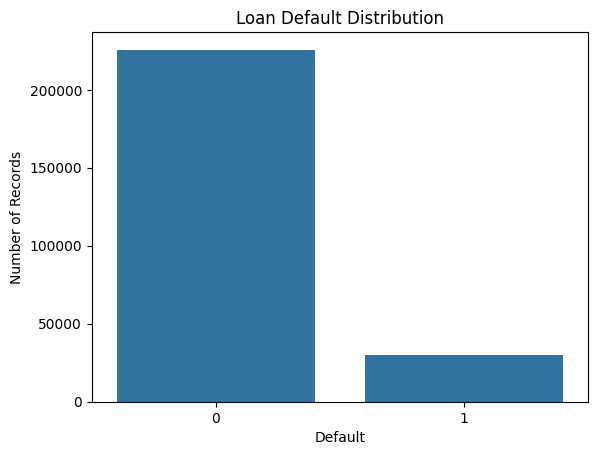

In [12]:
# Count target classes

print(df["Default"].value_counts())

# Calculate percentages

print(
    df["Default"].value_counts(normalize=True) * 100
)

# Visualize target distribution

sns.countplot(data=df, x="Default")

plt.title("Loan Default Distribution")
plt.xlabel("Default")
plt.ylabel("Number of Records")

plt.show()

In [13]:
# Create a copy of the original dataset

cleaned_df = df.copy()

# Remove the unique identifier

cleaned_df = cleaned_df.drop(columns=["LoanID"])

# Check the final dataset

print("Final dataset shape:", cleaned_df.shape)

cleaned_df.head()

Final dataset shape: (255347, 17)


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
